# Chapitre 10 - Cours 1 : la linéarisabilité

Répliquer les données protège des pannes, mais crée des copies qui peuvent diverger.
La garantie la plus forte qu'un système répliqué puisse offrir est de **se comporter
comme s'il n'existait qu'une seule copie** des données : c'est la **linéarisabilité**.
Ce notebook la définit précisément, construit un **vérificateur** qui décide si un
historique d'opérations est linéarisable, l'applique à des systèmes simulés (un registre
sur quorum, en particulier) et mesure ce qu'elle coûte. Il couvre l'introduction du chapitre et toute la section *Linearizability* (*What Makes a System Linearizable?*, *Relying on Linearizability*, *Implementing Linearizable Systems*, *The Cost of Linearizability*).

**Plan.**

1. Cohérence à terme ou cohérence forte : l'illusion d'une copie unique.
2. Qu'est-ce qui rend un système linéarisable ? Un vérificateur exécutable.
3. Linéarisabilité contre sérialisabilité.
4. Quand a-t-on besoin de linéarisabilité ?
5. Quelles réplications sont linéarisables ? Le piège des quorums.
6. Le coût de la linéarisabilité : CAP et délais réseau.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.consistency import Op
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Cohérence à terme ou cohérence forte : l'illusion d'une copie unique (section *Linearizability*)

Au chapitre 6, nous avons vu qu'une base répliquée peut renvoyer des
résultats **périmés** (une réplique en retard) ou **contradictoires** (des écritures
concurrentes sur plusieurs leaders). Deux philosophies s'opposent pour vivre avec :

- la **cohérence à terme** (eventual consistency) : la réplication est visible de
  l'application, qui doit gérer elle-même les incohérences et les conflits ; la seule
  promesse est que les répliques **convergent** si l'on cesse d'écrire. Promesse faible :
  elle ne dit rien de **quand** ;
- la **cohérence forte** : le système masque la réplication et se comporte **comme un
  seul nœud**. C'est plus simple pour le développeur, mais plus lent, et certaines pannes
  qu'un système à cohérence à terme tolère le rendent indisponible.

Quand les utilisateurs modifient des données hors connexion, la cohérence à terme est
inévitable (c'est le cas des sync engines et des logiciels local-first du chapitre
6). Quand les répliques vivent dans des centres de données reliés par un
réseau rapide et fiable, la cohérence forte est souvent abordable. Ce chapitre explore
l'approche forte selon trois axes : la **linéarisabilité** (définition précise de « forte »),
la **génération d'identifiants et d'horodatages** (cours 2), et le **consensus**, qui
permet d'être linéarisable tout en tolérant les pannes (cours 3 à 5).

**L'idée de la linéarisabilité** (aussi appelée cohérence atomique, cohérence forte,
cohérence immédiate ou externe) : le système doit donner l'**illusion d'une copie unique**
des données, sur laquelle chaque opération s'exécute **atomiquement**. Conséquence
directe : dès qu'une écriture est terminée, **toute** lecture qui commence ensuite, par
n'importe quel client, voit la nouvelle valeur. C'est une **garantie de fraîcheur**
(recency guarantee).

Voici un système qui ne la respecte pas. Inès et Bastien suivent sur leur téléphone la
finale de leur équipe. Le score final est écrit sur le leader, qui le réplique de façon
asynchrone à deux suiveurs. Inès recharge la page, tombe sur le suiveur 1 (à jour), voit
le score final et **le crie** à Bastien, qui recharge à son tour... et tombe sur le
suiveur 2, en retard : pour lui le match n'est pas fini.

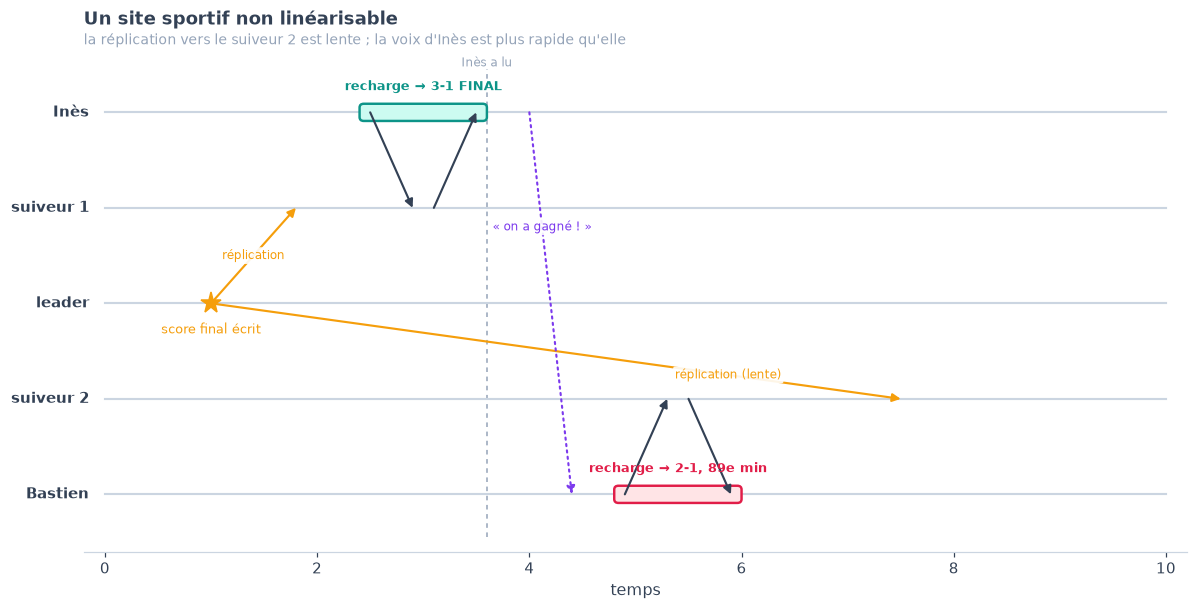

In [2]:
st = SpaceTime(["Inès", "suiveur 1", "leader", "suiveur 2", "Bastien"], t_max=10, width=11,
               title="Un site sportif non linéarisable",
               subtitle="la réplication vers le suiveur 2 est lente ; la voix d'Inès est plus rapide qu'elle")
st.event("leader", 1.0, "score final écrit", kind="star")
st.msg("leader", 1.0, "suiveur 1", 1.8, "réplication", color=AMBER)
st.msg("leader", 1.0, "suiveur 2", 7.5, "réplication (lente)", color=AMBER, label_pos=0.75)
st.op("Inès", 2.4, 3.6, "recharge → 3-1 FINAL", color=TEAL)
st.msg("Inès", 2.5, "suiveur 1", 2.9, "", color=SLATE)
st.msg("suiveur 1", 3.1, "Inès", 3.5, "", color=SLATE)
st.msg("Inès", 4.0, "Bastien", 4.4, "« on a gagné ! »", color=VIOLET, style="dotted", label_pos=0.3)
st.op("Bastien", 4.8, 6.0, "recharge → 2-1, 89e min", color=ROSE)
st.msg("Bastien", 4.9, "suiveur 2", 5.3, "", color=SLATE)
st.msg("suiveur 2", 5.5, "Bastien", 5.9, "", color=SLATE)
st.vline(3.6, "Inès a lu")
st.show()

Si les deux avaient rechargé **au même moment**, des résultats différents n'auraient
surpris personne. Mais Bastien **sait** qu'il a lancé sa requête **après** la réponse
reçue par Inès (il a entendu le cri) : il s'attend donc à un résultat au moins aussi
récent. La réponse périmée est une **violation de la linéarisabilité**. Remarquez que
l'anomalie n'est visible que grâce à un **second canal de communication** (la voix) :
nous y reviendrons en section 4.

> **À retenir.** La linéarisabilité donne l'illusion d'une copie unique, modifiée
> atomiquement : une lecture qui commence après la fin d'une écriture (ou d'une autre
> lecture) doit voir une valeur au moins aussi récente. C'est une garantie de fraîcheur.

## 2. Qu'est-ce qui rend un système linéarisable ? (section *What Makes a System Linearizable?*)

**Le modèle.** On raisonne sur un **registre** $x$ (en pratique une clé d'un magasin
clé-valeur, une ligne, un document) et sur des opérations vues **depuis les clients** :

- `read(x) ⇒ v` : le client lit $x$ et la base répond $v$ ;
- `write(x, v) ⇒ ok` : le client écrit $v$ dans $x$ ;
- `cas(x, old, new) ⇒ ok / échec` : compare-and-set atomique, qui écrit `new` seulement
  si la valeur courante vaut `old` (chapitre 8).

Chaque opération est un **intervalle** de temps : de l'envoi de la requête à la réception
de la réponse. Le client ne sait pas **quand** la base l'a réellement traitée, seulement
que c'était **quelque part dans l'intervalle**. Deux opérations dont les intervalles se
chevauchent sont **concurrentes**.

**La définition.** Un historique est linéarisable s'il existe un **point de
linéarisation** dans l'intervalle de chaque opération tel que, rangées dans l'ordre de
ces points, les opérations forment une exécution **séquentielle valide** du registre
(chaque lecture renvoie la dernière valeur écrite avant elle). Deux conséquences :

1. si A se termine avant que B ne commence, A précède B (le temps réel est respecté) ;
2. une lecture concurrente d'une écriture peut renvoyer l'ancienne **ou** la nouvelle
   valeur, mais une fois qu'une lecture a vu la nouvelle, **toutes les lectures
   suivantes** doivent la voir : la valeur ne peut pas « clignoter ».

**Un vérificateur exécutable.** `cs.check_linearizable` cherche un tel ordre : à chaque
étape, il essaie de placer en tête une opération qui peut l'être (aucune opération
restante ne s'est terminée avant son appel) et dont le résultat est cohérent avec l'état
du registre, puis recommence ; en cas d'impasse, il revient en arrière. Il mémorise les
couples (opérations déjà placées, valeur du registre) déjà explorés : c'est
l'algorithme de Wing et Gong amélioré par Lowe, celui qu'utilisent les outils de test
comme Knossos (Jepsen) ou Porcupine. Appliquons-le à trois historiques où C écrit 1
pendant que A et B lisent.

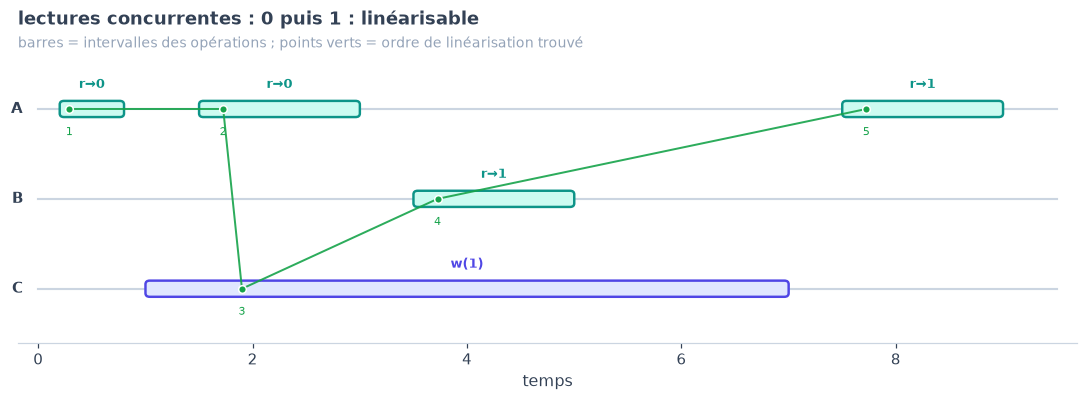

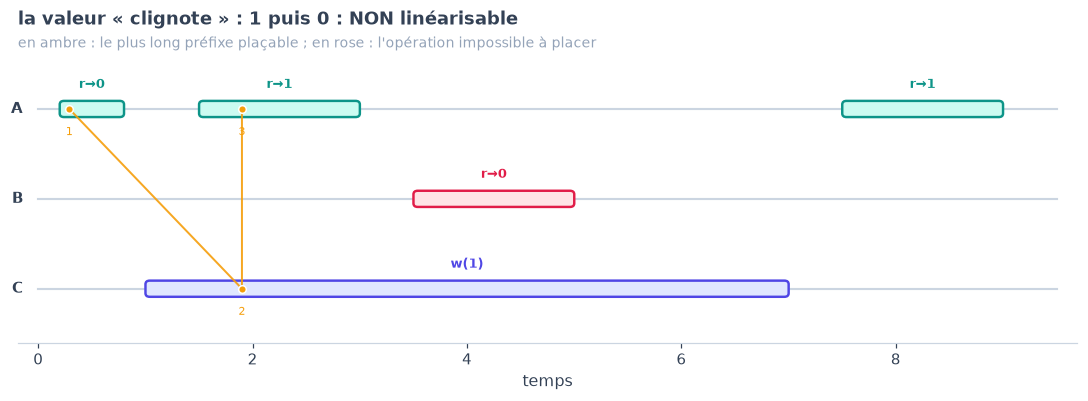

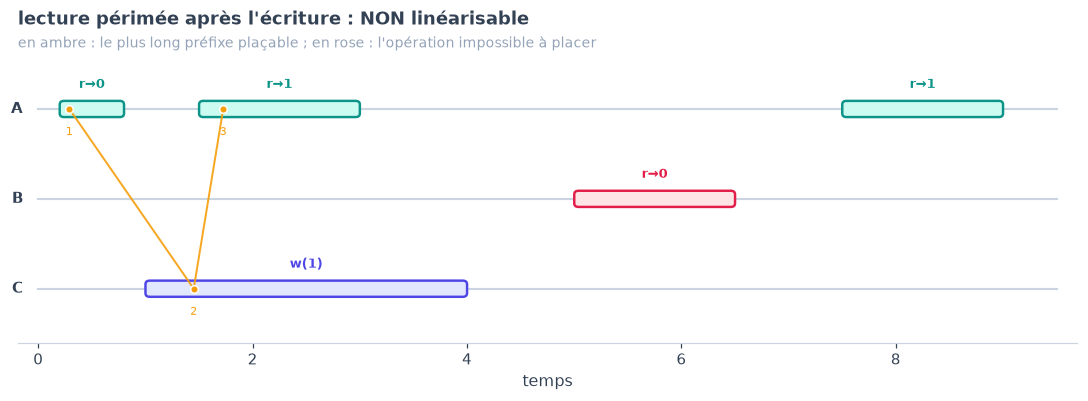

,historique,linéarisable,états_explorés
0,lectures concurrentes : 0 puis 1,True,6
1,la valeur « clignote » : 1 puis 0,False,4
2,lecture périmée après l'écriture,False,4


In [3]:
H = {
    "lectures concurrentes : 0 puis 1": [Op("C", "write", 1, "ok", 1.0, 7.0), Op("A", "read", None, 0, 0.2, 0.8),
                                       Op("A", "read", None, 0, 1.5, 3.0), Op("B", "read", None, 1, 3.5, 5.0),
                                       Op("A", "read", None, 1, 7.5, 9.0)],
    "la valeur « clignote » : 1 puis 0": [Op("C", "write", 1, "ok", 1.0, 7.0), Op("A", "read", None, 0, 0.2, 0.8),
                                        Op("A", "read", None, 1, 1.5, 3.0), Op("B", "read", None, 0, 3.5, 5.0),
                                        Op("A", "read", None, 1, 7.5, 9.0)],
    "lecture périmée après l'écriture": [Op("C", "write", 1, "ok", 1.0, 4.0), Op("A", "read", None, 0, 0.2, 0.8),
                                       Op("A", "read", None, 1, 1.5, 3.0), Op("B", "read", None, 0, 5.0, 6.5),
                                       Op("A", "read", None, 1, 7.5, 9.0)],
}
rows = []
for nom, h in H.items():
    res = cs.check_linearizable(h)
    rows.append(dict(historique=nom, linéarisable=res.ok, états_explorés=res.explored))
    st = cs.plot_history(h, title=f"{nom} : {'linéarisable' if res.ok else 'NON linéarisable'}",
                         subtitle="barres = intervalles des opérations ; points verts = ordre de linéarisation trouvé"
                         if res.ok else "en ambre : le plus long préfixe plaçable ; en rose : l'opération impossible à placer",
                         result=res, clients=["A", "B", "C"], t_max=9.5, width=10,
                         highlight=res.blocking(h)[:1])
    st.show()
pd.DataFrame(rows)

Dans le premier historique, la lecture de B (qui renvoie 1) est concurrente de
l'écriture : le vérificateur place l'écriture **à l'intérieur** de son intervalle, juste
avant la lecture de B. Dans le deuxième, A a vu 1 puis B, qui commence **après** la
réponse à A, voit 0 : aucun placement des points ne permet de revenir à l'ancienne valeur.
C'est exactement la situation d'Inès et Bastien. Dans le troisième, B lit 0 alors que
l'écriture est **terminée** avant même le début de sa lecture.

**Un exemple plus riche, avec des CAS.** Quatre clients, des écritures concurrentes et
des compare-and-set. Les requêtes ne sont pas traitées dans l'ordre d'envoi : c'est
permis tant qu'elles sont concurrentes (un message a pu être retardé sur le réseau).

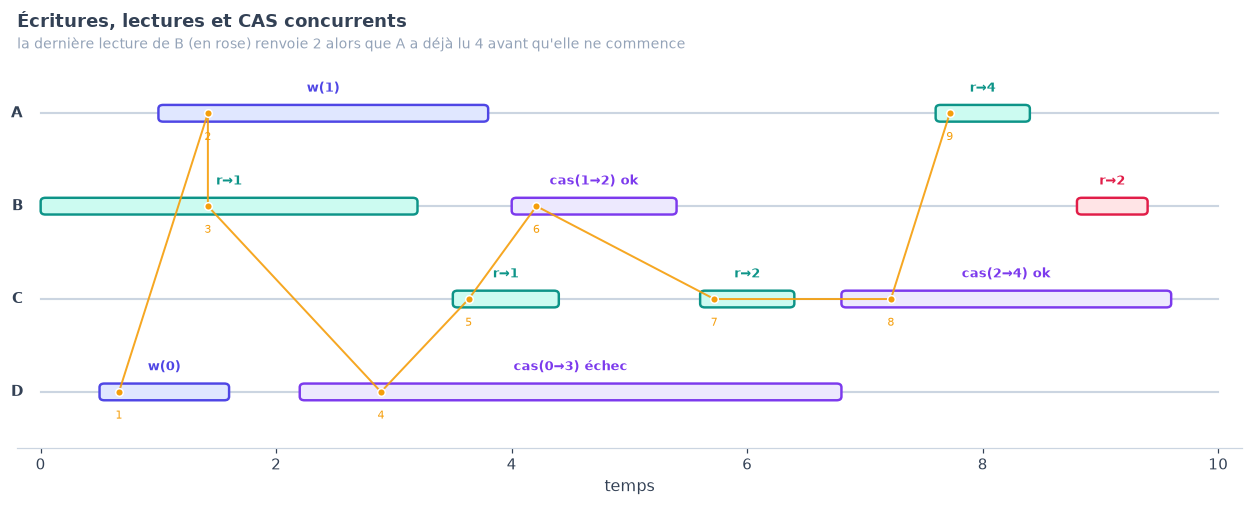

linéarisable : False ; opérations placées : 9 sur 10
ordre partiel trouvé : w(0) (D) ; w(1) (A) ; r→1 (B) ; cas(0→3) échec (D) ; r→1 (C) ; cas(1→2) ok (B) ; r→2 (C) ; cas(2→4) ok (C) ; r→4 (A)


In [4]:
riche = [
    Op("B", "read", None, 1, 0.0, 3.2),
    Op("D", "write", 0, "ok", 0.5, 1.6),
    Op("A", "write", 1, "ok", 1.0, 3.8),
    Op("C", "read", None, 1, 3.5, 4.4),
    Op("B", "cas", (1, 2), True, 4.0, 5.4),
    Op("C", "read", None, 2, 5.6, 6.4),
    Op("D", "cas", (0, 3), False, 2.2, 6.8),
    Op("C", "cas", (2, 4), True, 6.8, 9.6),
    Op("A", "read", None, 4, 7.6, 8.4),
    Op("B", "read", None, 2, 8.8, 9.4),
]
res = cs.check_linearizable(riche)
st = cs.plot_history(riche, title="Écritures, lectures et CAS concurrents",
                     subtitle="la dernière lecture de B (en rose) renvoie 2 alors que A a déjà lu 4 avant qu'elle ne commence",
                     result=res, clients=["A", "B", "C", "D"], t_max=10, width=11.5, highlight=res.blocking(riche)[:1])
st.show()
print("linéarisable :", res.ok, "; opérations placées :", len(res.order), "sur", len(riche))
print("ordre partiel trouvé :", " ; ".join(cs.op_label(riche[i]) + f" ({riche[i].client})" for i in res.order))

Les neuf premières opérations se linéarisent (ligne ambre) : la base a traité
l'écriture de D, puis celle de A, puis la lecture de B (qui renvoie donc 1 bien qu'elle
ait été envoyée **avant** les deux écritures) ; le CAS de D échoue car la valeur n'est
plus 0 ; ceux de B puis de C réussissent. La dernière lecture de B est concurrente du
CAS de C qui fait passer $x$ de 2 à 4 : seule, elle pourrait renvoyer 2. Mais A a **déjà
lu 4** avant que la lecture de B ne commence : B n'a plus le droit de voir une valeur
plus ancienne.

Tester la linéarisabilité d'un vrai système revient à enregistrer les instants de toutes
les requêtes et réponses, puis à chercher un ordre valide : c'est ce que fait Jepsen. Le
problème est NP-complet dans le cas général ; la mémoïsation le rend praticable sur des
historiques courts (l'exercice 10.2 mesure ce coût).

**Modèles plus faibles.** Comme il existe des niveaux d'isolation plus faibles que la
sérialisabilité, il existe des modèles de cohérence plus faibles que la linéarisabilité :
lire ses propres écritures, lectures monotones, préfixe cohérent (chapitre
6). La linéarisabilité les implique tous : c'est le modèle le plus fort
d'usage courant.

> **À retenir.** Un historique est linéarisable si l'on peut placer dans l'intervalle de
> chaque opération un point instantané tel que la suite des points soit une exécution
> séquentielle valide. On le teste en cherchant cet ordre : c'est coûteux mais exécutable.

## 3. Linéarisabilité contre sérialisabilité (encadré *Linearizability Versus Serializability*)

Les deux mots évoquent « un ordre séquentiel », mais ce sont deux garanties différentes :

| | Sérialisabilité | Linéarisabilité |
|---|---|---|
| porte sur | des **transactions** (plusieurs objets) | des opérations sur **un objet** (registre) |
| promet | même résultat qu'une exécution en série, dans **un** ordre quelconque | ordre compatible avec le **temps réel** |
| empêche le write skew ? | oui | non (pas de transactions) |
| interdit les lectures périmées ? | non | oui (garantie de fraîcheur) |

Une base peut offrir les deux : on parle alors de **sérialisabilité stricte** (strict
serializability, ou strong one-copy serializability). Un SGBD sur un seul nœud est en
général linéarisable. Pour une base distribuée qui utilise une méthode optimiste comme
SSI (chapitre 8), c'est plus délicat : la sérialisabilité stricte exige
une coordination coûteuse entre transactions, que certaines bases offrent (Spanner,
FoundationDB) et d'autres non (CockroachDB garantit la sérialisabilité et une partie
seulement de la fraîcheur). Les deux axes sont d'ailleurs largement **indépendants**.

Un exemple montre qu'une exécution peut être sérialisable sans être linéarisable : la
transaction T2 commence **après** la validation de T1 mais lit un **instantané ancien**
(une réplique en retard, par exemple). L'ordre série « T2 puis T1 » explique ses
lectures : c'est sérialisable. Mais T2 ne voit pas une écriture terminée avant son
début : ce n'est pas linéarisable.

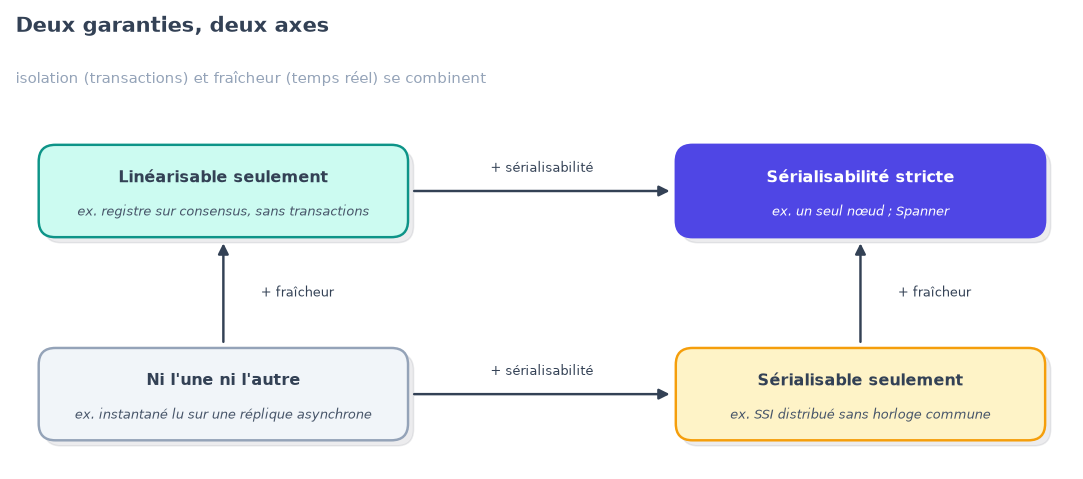

In [5]:
d = Diagram(11.5, 4.0, title="Deux garanties, deux axes", subtitle="isolation (transactions) et fraîcheur (temps réel) se combinent")
d.box("aucune", 2.3, 0.8, "Ni l'une ni l'autre", sub="ex. instantané lu sur une réplique asynchrone", color=GRAY, w=4.0, h=1.0)
d.box("ser", 9.2, 0.8, "Sérialisable seulement", sub="ex. SSI distribué sans horloge commune", color=AMBER, w=4.0, h=1.0)
d.box("lin", 2.3, 3.0, "Linéarisable seulement", sub="ex. registre sur consensus, sans transactions", color=TEAL, w=4.0, h=1.0)
d.box("strict", 9.2, 3.0, "Sérialisabilité stricte", sub="ex. un seul nœud ; Spanner", color=INDIGO, w=4.0, h=1.0, filled=True)
d.arrow("aucune", "ser", "+ sérialisabilité", label_offset=(0, 0.25))
d.arrow("aucune", "lin", "+ fraîcheur", label_offset=(0.8, 0))
d.arrow("lin", "strict", "+ sérialisabilité", label_offset=(0, 0.25))
d.arrow("ser", "strict", "+ fraîcheur", label_offset=(0.8, 0))
d.show()

> **À retenir.** Sérialisabilité : des transactions qui se comportent comme si elles
> étaient exécutées en série, dans un ordre quelconque. Linéarisabilité : un objet qui se
> comporte comme une copie unique, dans l'ordre du temps réel. Les deux ensemble forment
> la sérialisabilité stricte.

## 4. Quand a-t-on besoin de linéarisabilité ? (section *Relying on Linearizability*)

Un score périmé de quelques secondes ne fait de mal à personne. Mais trois situations
**exigent** la linéarisabilité pour être correctes.

**Verrous et élection de leader** (*Locking and leader election*). Une base à leader
unique doit garantir qu'il n'y a **qu'un** leader (sinon, cerveau divisé). Une manière
d'élire un leader est un **bail** (lease) : chaque nœud tente de l'acquérir, un seul doit
réussir. Quelle que soit l'implémentation, cette acquisition doit être linéarisable. Les
services de coordination comme ZooKeeper et etcd fournissent ce stockage linéarisable
tolérant aux pannes, grâce à un algorithme de consensus (cours 3 à 5). Nuance : ZooKeeper
linéarise les écritures mais peut servir des lectures périmées (un suiveur peut être en
retard) ; etcd linéarise aussi les lectures par défaut depuis sa version 3. Certaines
bases utilisent des verrous distribués à grain très fin : Oracle RAC prend un verrou par
page de disque partagé, sur le chemin critique de chaque transaction, et réserve à cet
effet un réseau d'interconnexion dédié.

**Contraintes d'unicité** (*Constraints and uniqueness guarantees*). Deux personnes qui
créent en même temps le même nom d'utilisateur : l'une doit recevoir une erreur. C'est
un verrou sur le nom, ou un CAS « si le nom est libre, l'attribuer ». Même chose pour un
solde qui ne doit pas devenir négatif, un stock à ne pas survendre, un siège à ne pas
réserver deux fois : il faut **une valeur à jour sur laquelle tous les nœuds
s'accordent**. On peut parfois relâcher la contrainte (surréserver un vol puis
dédommager, chapitre 13) ; une contrainte d'unicité stricte, elle, exige la
linéarisabilité (les clés étrangères ou contraintes d'attributs, non).

**Dépendances entre canaux** (*Cross-channel timing dependencies*). Inès et Bastien ont
vu l'anomalie parce qu'un **second canal** (la voix) a couru plus vite que la
réplication. Même chose dans un système informatique : un serveur web enregistre une
vidéo dans un stockage de fichiers, puis envoie par une file de messages l'ordre de la
transcoder.

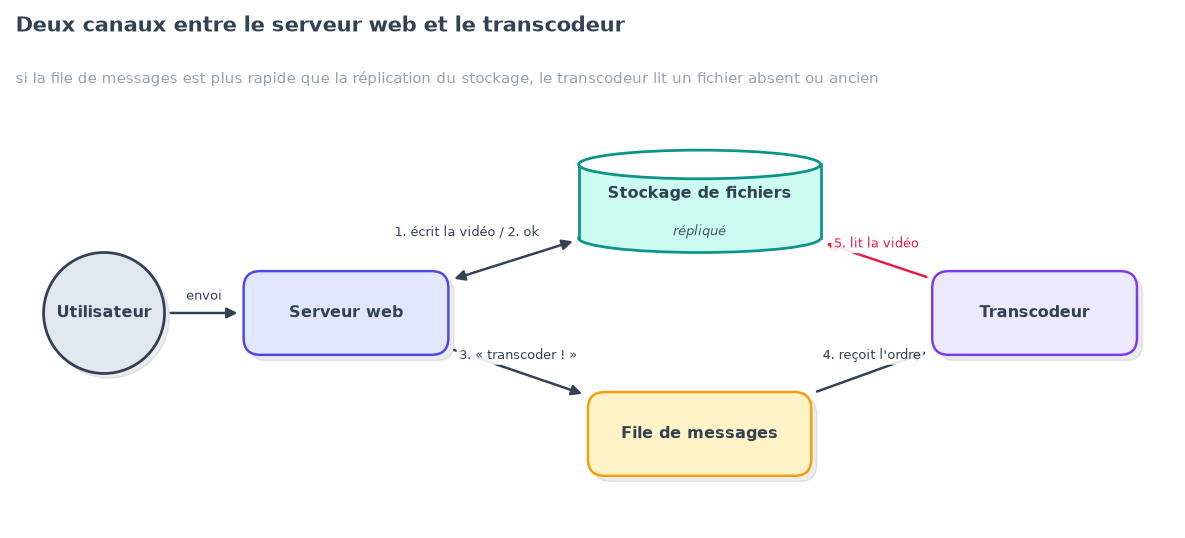

In [6]:
d = Diagram(12.5, 4.6, title="Deux canaux entre le serveur web et le transcodeur",
            subtitle="si la file de messages est plus rapide que la réplication du stockage, le transcodeur lit un fichier absent ou ancien")
d.box("u", 1.0, 2.3, "Utilisateur", kind="user", w=1.3, color=SLATE)
d.box("web", 3.6, 2.3, "Serveur web", color=INDIGO)
d.box("st", 7.4, 3.5, "Stockage de fichiers", sub="répliqué", color=TEAL, kind="db", w=2.6, h=1.1)
d.box("q", 7.4, 1.0, "File de messages", color=AMBER, w=2.4)
d.box("tr", 11.0, 2.3, "Transcodeur", color=VIOLET, w=2.2)
d.arrow("u", "web", "envoi")
d.arrow("web", "st", "1. écrit la vidéo / 2. ok", both=True, label_offset=(-0.5, 0.3))
d.arrow("web", "q", "3. « transcoder ! »")
d.arrow("q", "tr", "4. reçoit l'ordre")
d.arrow("tr", "st", "5. lit la vidéo", color=ROSE)
d.show()

Si le stockage n'est pas linéarisable (une réplique lit en retard), le transcodeur peut
lire l'ancienne version du fichier, ou rien. Modélisons : le retard de réplication de la
réplique lue par le transcodeur suit une loi log-normale de médiane $L$, l'acheminement
de l'ordre par la file (étapes 3 et 4) une log-normale de médiane $Q$. Le transcodeur lit
une version périmée si l'ordre arrive **avant** la fin de la réplication.

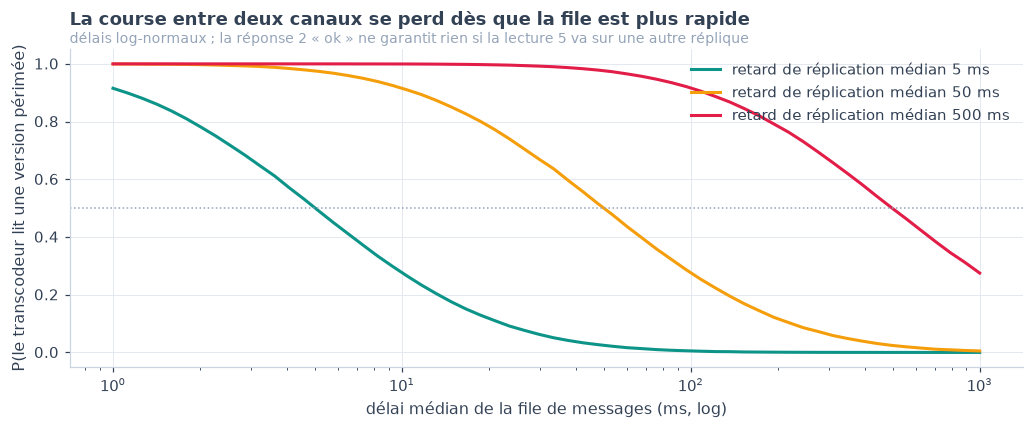

In [7]:
n = 200_000
Q = np.geomspace(1, 1000, 60)            # médiane du délai de la file (ms)
fig, ax = plt.subplots(figsize=(9.5, 4))
for L, c in [(5, TEAL), (50, AMBER), (500, ROSE)]:
    lag = L * rng.lognormal(0, 1.0, n)
    p = [np.mean(q * rng.lognormal(0, 0.6, n) < lag) for q in Q]
    ax.plot(Q, p, color=c, label=f"retard de réplication médian {L} ms")
ax.set_xscale("log")
ax.set_xlabel("délai médian de la file de messages (ms, log)")
ax.set_ylabel("P(le transcodeur lit une version périmée)")
ax.set_title("La course entre deux canaux se perd dès que la file est plus rapide")
subtitle(ax, "délais log-normaux ; la réponse 2 « ok » ne garantit rien si la lecture 5 va sur une autre réplique")
ax.axhline(0.5, color=GRAY, lw=1, ls=":")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

La probabilité d'incident vaut environ 1/2 quand les deux canaux ont des délais du
même ordre, et tend vers 1 quand la file est nettement plus rapide que la réplication
(le cas usuel : une file en mémoire contre un stockage répliqué entre centres de
données). Et l'erreur est **définitive** : la vidéo transcodée ne correspondra jamais à
l'originale. Même course avec une notification push suivie d'une lecture sur une réplique
en retard. La linéarisabilité n'est pas la seule parade (si l'on contrôle le second
canal, on peut y joindre la version attendue, comme pour « lire ses propres écritures »
au chapitre 6), mais c'est la plus simple à raisonner.

> **À retenir.** La linéarisabilité est indispensable quand plusieurs nœuds doivent
> s'accorder sur **une** valeur à jour (verrou, leader, unicité, stock) et quand un second
> canal de communication peut révéler qu'une réplique est en retard.

## 5. Quelles réplications sont linéarisables ? Le piège des quorums (section *Implementing Linearizable Systems*)

La façon la plus simple d'être linéarisable : n'avoir **réellement qu'une copie**. Mais
elle ne tolère aucune panne. Passons en revue les réplications du chapitre
6 :

| Réplication | Linéarisable ? | Pourquoi |
|---|---|---|
| leader unique | **potentiellement** | si toutes les lectures et écritures passent par le leader... et si l'on est **sûr** de qui est le leader (un leader déchu qui se croit encore leader viole la garantie) ; une bascule avec réplication asynchrone peut perdre des écritures validées |
| consensus | **probablement** | leader unique avec élection et bascule automatiques, conçues pour empêcher le cerveau divisé (ZooKeeper : Zab, etcd : Raft) ; mais une lecture servie par un nœud sans vérifier qu'il est encore leader peut être périmée (cours 4) |
| multi-leader | **non** | écritures concurrentes sur plusieurs nœuds, conflits à résoudre |
| sans leader (Dynamo) | **probablement pas** | LWW sur horloges physiques (Cassandra) : non, à cause du décalage des horloges ; et même avec des quorums $w + r > n$, voir ci-dessous |

Partitionner une base à leader unique (un leader par shard) ne change rien : la
linéarisabilité ne porte que sur un objet. Les transactions entre shards sont une autre
affaire (chapitre 8).

**Le piège.** Intuitivement, des quorums stricts ($w + r > n$) devraient suffire : toute
lecture recoupe la dernière écriture. Ce n'est pas le cas quand les délais varient.
Reconstituons le scénario : $n = 3$, l'écrivain envoie $x = 1$ aux trois répliques
($w = 3$) ; le message vers R1 arrive vite, ceux vers R2 et R3 traînent.

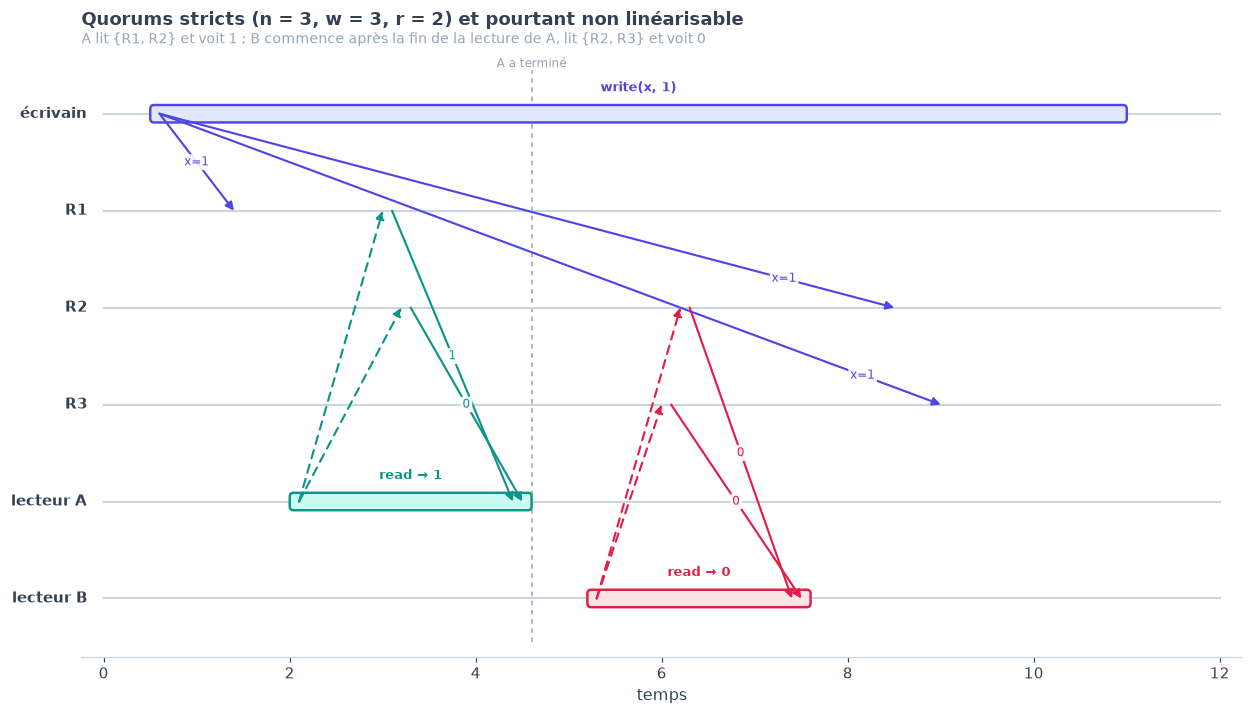

historique vu des clients linéarisable ? False


In [8]:
st = SpaceTime(["écrivain", "R1", "R2", "R3", "lecteur A", "lecteur B"], t_max=12, width=11.5,
               title="Quorums stricts (n = 3, w = 3, r = 2) et pourtant non linéarisable",
               subtitle="A lit {R1, R2} et voit 1 ; B commence après la fin de la lecture de A, lit {R2, R3} et voit 0")
st.op("écrivain", 0.5, 11.0, "write(x, 1)", color=INDIGO)
st.msg("écrivain", 0.6, "R1", 1.4, "x=1", color=INDIGO)
st.msg("écrivain", 0.6, "R2", 8.5, "x=1", color=INDIGO, label_pos=0.85)
st.msg("écrivain", 0.6, "R3", 9.0, "x=1", color=INDIGO, label_pos=0.9)
st.op("lecteur A", 2.0, 4.6, "read → 1", color=TEAL)
st.msg("lecteur A", 2.1, "R1", 3.0, "", color=TEAL, style="dashed")
st.msg("lecteur A", 2.1, "R2", 3.2, "", color=TEAL, style="dashed")
st.msg("R1", 3.1, "lecteur A", 4.4, "1", color=TEAL)
st.msg("R2", 3.3, "lecteur A", 4.5, "0", color=TEAL)
st.op("lecteur B", 5.2, 7.6, "read → 0", color=ROSE)
st.msg("lecteur B", 5.3, "R2", 6.2, "", color=ROSE, style="dashed")
st.msg("lecteur B", 5.3, "R3", 6.0, "", color=ROSE, style="dashed")
st.msg("R2", 6.3, "lecteur B", 7.4, "0", color=ROSE)
st.msg("R3", 6.1, "lecteur B", 7.5, "0", color=ROSE)
st.vline(4.6, "A a terminé")
st.show()

quorum_hist = [Op("W", "write", 1, "ok", 0.5, 11.0), Op("A", "read", None, 1, 2.0, 4.6), Op("B", "read", None, 0, 5.2, 7.6)]
print("historique vu des clients linéarisable ?", cs.check_linearizable(quorum_hist).ok)

La condition de quorum est respectée, mais B, qui commence **après** la fin de A, voit
une valeur **plus ancienne** que A. C'est encore Inès et Bastien.

**Réparer : l'algorithme ABD.** On peut rendre un registre sur quorum linéarisable
(Attiya, Bar-Noy et Dolev) en ajoutant un second aller-retour à chaque opération :

- le **lecteur** réécrit la valeur la plus récente qu'il a vue sur un quorum (réparation
  **synchrone**) **avant** de répondre : aucune lecture ultérieure ne peut donc voir plus
  ancien ;
- l'**écrivain** lit d'abord l'horodatage le plus élevé sur un quorum et écrit avec un
  horodatage plus grand.

Riak ne fait pas cette réparation synchrone (trop coûteuse) ; Cassandra l'attend sur les
lectures en quorum, mais perd la linéarisabilité à cause des horodatages LWW issus des
horloges physiques. Et seules les lectures et écritures se réparent ainsi : un **CAS**
linéarisable exige un algorithme de consensus.

Mesurons. `cs.run_quorum_register` simule sur `ddia.sim` trois répliques, deux écrivains
(horodatages formés d'un compteur local et du nom de l'écrivain) et deux lecteurs, avec
des délais log-normaux de dispersion $\sigma$. Pour chaque graine, on vérifie
l'historique obtenu.

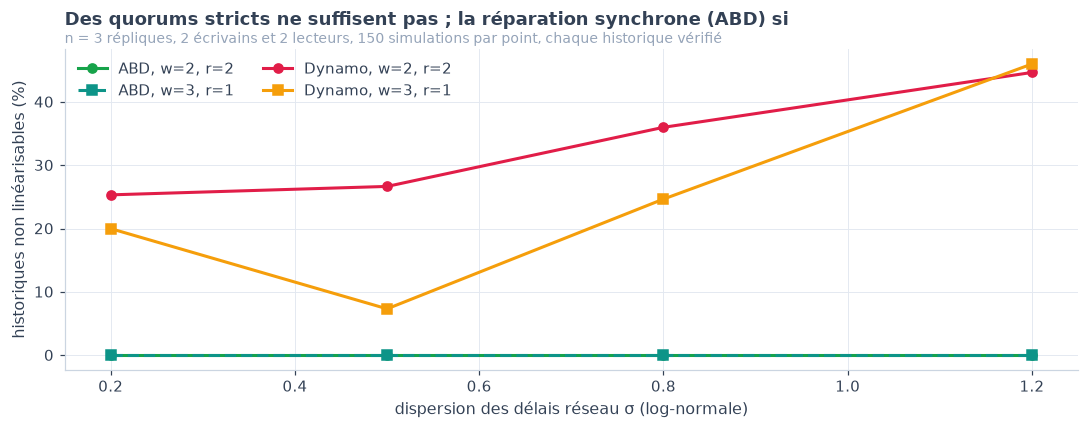

mode         abd            dynamo         
quorums w=2, r=2 w=3, r=1 w=2, r=2 w=3, r=1
sigma                                      
0.2          0.0      0.0    0.253    0.200
0.5          0.0      0.0    0.267    0.073
0.8          0.0      0.0    0.360    0.247
1.2          0.0      0.0    0.447    0.460

In [9]:
rows = []
for sigma in [0.2, 0.5, 0.8, 1.2]:
    for mode in ["dynamo", "abd"]:
        for (w, r) in [(2, 2), (3, 1)]:
            bad = 0
            for s in range(150):
                h, _ = cs.run_quorum_register(mode=mode, w=w, r=r, seed=s, sigma=sigma, n_writers=2)
                bad += not cs.check_linearizable(h).ok
            rows.append(dict(sigma=sigma, mode=mode, quorums=f"w={w}, r={r}", taux=bad / 150))
Q_ = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4))
styles = {("dynamo", "w=2, r=2"): (ROSE, "-o"), ("dynamo", "w=3, r=1"): (AMBER, "-s"),
          ("abd", "w=2, r=2"): (GREEN, "-o"), ("abd", "w=3, r=1"): (TEAL, "--s")}
for (mode, q), g in Q_.groupby(["mode", "quorums"]):
    c, ls = styles[(mode, q)]
    ax.plot(g.sigma, g.taux * 100, ls, color=c, label=f"{'Dynamo' if mode == 'dynamo' else 'ABD'}, {q}")
ax.set_xlabel("dispersion des délais réseau σ (log-normale)")
ax.set_ylabel("historiques non linéarisables (%)")
ax.set_title("Des quorums stricts ne suffisent pas ; la réparation synchrone (ABD) si")
subtitle(ax, "n = 3 répliques, 2 écrivains et 2 lecteurs, 150 simulations par point, chaque historique vérifié")
ax.legend(ncol=2, loc="upper left")
plt.tight_layout(); plt.show()
Q_.pivot_table(index="sigma", columns=["mode", "quorums"], values="taux")

Sans réparation synchrone, une part notable des historiques (de 7 % à 45 % selon les
cas) viole la linéarisabilité, et la tendance est à la hausse quand les délais se
dispersent. Avec deux écrivains s'ajoute un second
défaut : deux écritures peuvent recevoir le même compteur, départagé par le **nom** de
l'écrivain et non par l'ordre réel, si bien qu'une écriture terminée peut être écrasée
par une écriture **antérieure**. ABD n'a aucune violation sur les 1 200 simulations (ses
deux aller-retours ordonnent les horodatages en fonction de ce que chacun a lu).

Le prix ? Une lecture ABD fait **deux** allers-retours de quorum au lieu d'un.

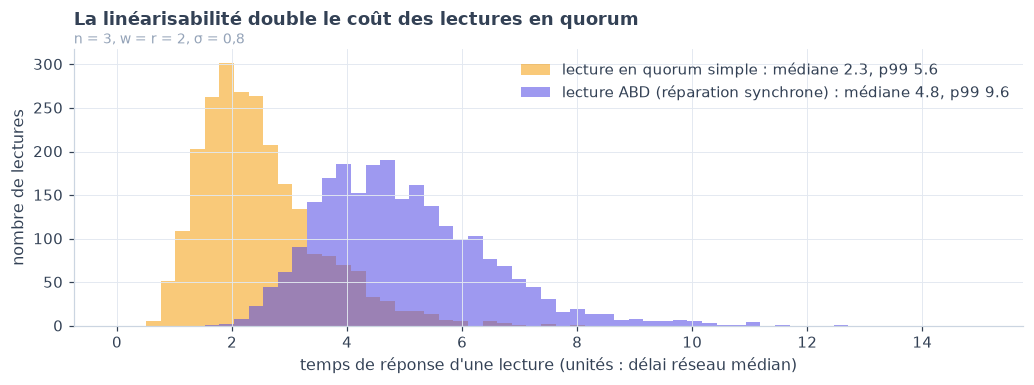

In [10]:
lat = {}
for mode in ["dynamo", "abd"]:
    lat[mode] = []
    for s in range(150):
        h, _ = cs.run_quorum_register(mode=mode, seed=s, sigma=0.8, n_writers=2)
        lat[mode] += [o.t_return - o.t_call for o in h if o.kind == "read"]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
bins = np.linspace(0, 15, 60)
for mode, c, lab in [("dynamo", AMBER, "lecture en quorum simple"), ("abd", INDIGO, "lecture ABD (réparation synchrone)")]:
    v = np.array(lat[mode])
    ax.hist(v, bins=bins, color=c, alpha=0.55, label=f"{lab} : médiane {np.median(v):.1f}, p99 {np.percentile(v, 99):.1f}")
ax.set_xlabel("temps de réponse d'une lecture (unités : délai réseau médian)")
ax.set_ylabel("nombre de lectures")
ax.set_title("La linéarisabilité double le coût des lectures en quorum")
subtitle(ax, "n = 3, w = r = 2, σ = 0,8")
ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Leader unique : linéarisable si l'on sait qui est le leader ; consensus :
> conçu pour ; multi-leader : non ; sans leader : prudemment, non, même avec $w + r > n$.
> Un quorum devient linéarisable avec une réparation synchrone (ABD), au prix d'un second
> aller-retour, et un CAS demande un consensus.

## 6. Le coût de la linéarisabilité : CAP et délais réseau (section *The Cost of Linearizability*)

Prenons une base répliquée sur deux centres de données, et coupons le lien entre eux
(une **partition réseau**) : chaque site fonctionne, ses clients le joignent, mais les
sites ne se parlent plus.

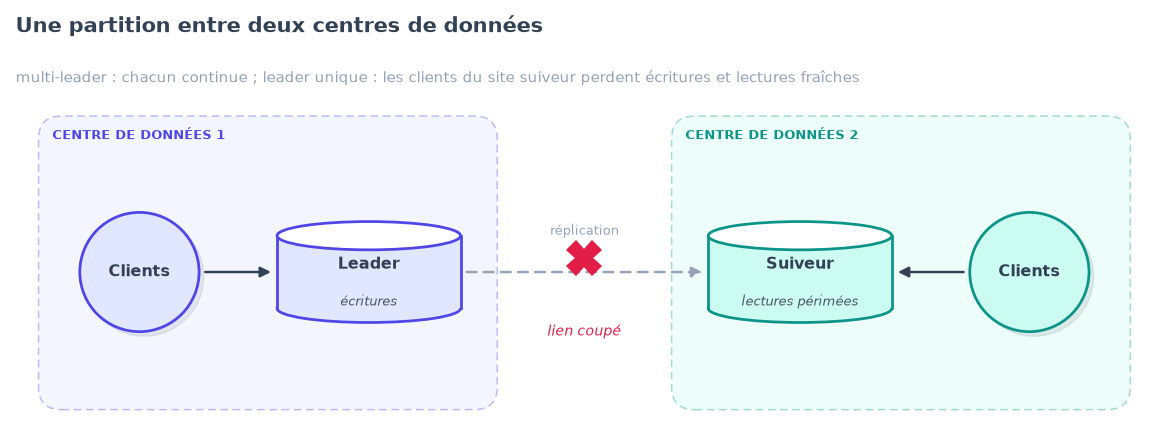

In [11]:
d = Diagram(12.5, 3.6, title="Une partition entre deux centres de données",
            subtitle="multi-leader : chacun continue ; leader unique : les clients du site suiveur perdent écritures et lectures fraîches")
d.group(0.3, 0.2, 5.3, 3.4, "centre de données 1", color=INDIGO)
d.group(7.2, 0.2, 12.2, 3.4, "centre de données 2", color=TEAL)
d.box("c1", 1.4, 1.7, "Clients", kind="user", w=1.3, color=INDIGO)
d.box("db1", 3.9, 1.7, "Leader", sub="écritures", color=INDIGO, kind="db", w=2.0, h=1.1)
d.box("db2", 8.6, 1.7, "Suiveur", sub="lectures périmées", color=TEAL, kind="db", w=2.0, h=1.1)
d.box("c2", 11.1, 1.7, "Clients", kind="user", w=1.3, color=TEAL)
d.arrow("c1", "db1")
d.arrow("c2", "db2")
d.arrow("db1", "db2", "réplication", style="dashed", color=GRAY, label_offset=(0, 0.45))
d.ax.plot([6.25], [1.85], marker="X", color=ROSE, markersize=22, zorder=8)
d.note(6.25, 1.05, "lien coupé", color=ROSE)
d.show()

- **Multi-leader** : chaque site accepte les écritures et les échangera au
  rétablissement. Le service reste **disponible**, mais n'est pas linéarisable.
- **Leader unique** : toute écriture et toute lecture linéarisable doit aller au leader.
  Pendant la coupure, les clients du site 2 ne peuvent plus écrire ni lire frais : pour
  eux, l'application est **indisponible** (ils peuvent lire le suiveur, mais périmé).

**Le théorème CAP** (*The CAP theorem*). Ce n'est pas propre à ces deux architectures :
**tout** système linéarisable a ce problème, sur tout réseau non fiable, même dans un
seul site.

- si l'application **exige** la linéarisabilité, une réplique coupée des autres doit
  attendre ou répondre une erreur : elle est indisponible (choix « CP », cohérent en cas
  de partition) ;
- si elle ne l'exige pas, chaque réplique peut traiter les requêtes seule : disponible
  mais non linéarisable (choix « AP »).

Simulons une journée de 24 heures avec une coupure de 3 heures, et la part des requêtes
servies dans chaque site selon le choix.

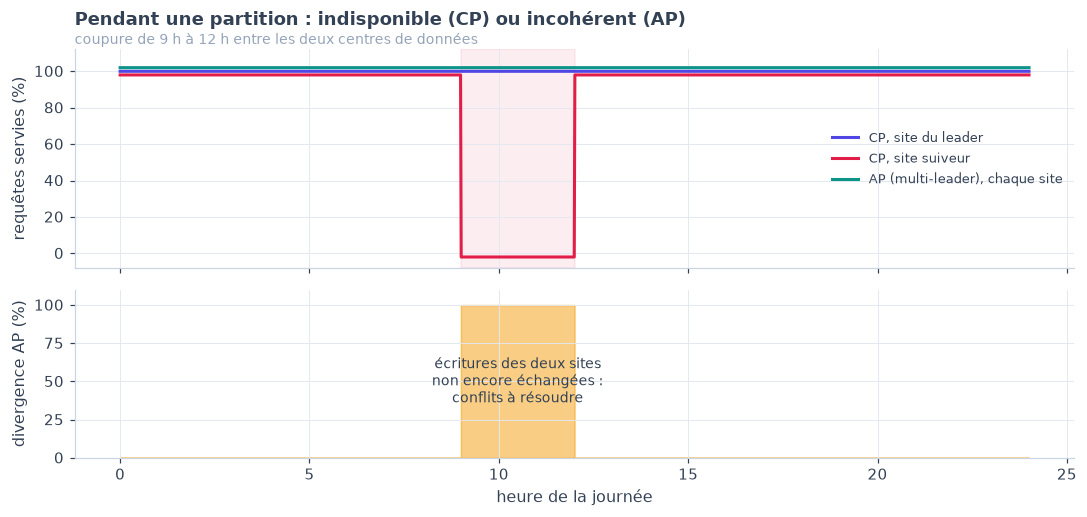

CP : disponibilité du site suiveur sur la journée = 87.5%


In [12]:
t = np.linspace(0, 24, 24 * 60)
cut = (t >= 9) & (t < 12)
served = {
    "CP, site du leader": np.ones_like(t),
    "CP, site suiveur": np.where(cut, 0.0, 1.0),
    "AP (multi-leader), chaque site": np.ones_like(t),
}
stale = np.where(cut, 1.0, 0.0)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
for (lab, y), c, off in zip(served.items(), [INDIGO, ROSE, TEAL], [0.0, -0.02, 0.02]):
    ax.plot(t, y * 100 + off * 100, color=c, label=lab)
ax.axvspan(9, 12, color=ROSE, alpha=0.08)
ax.set_ylabel("requêtes servies (%)")
ax.set_ylim(-8, 112)
ax.set_title("Pendant une partition : indisponible (CP) ou incohérent (AP)")
subtitle(ax, "coupure de 9 h à 12 h entre les deux centres de données")
ax.legend(loc="center right", fontsize=8.5)
ax2.fill_between(t, 0, stale * 100, color=AMBER, alpha=0.5, step="mid")
ax2.set_ylabel("divergence AP (%)")
ax2.set_xlabel("heure de la journée")
ax2.text(10.5, 50, "écritures des deux sites\nnon encore échangées :\nconflits à résoudre", ha="center", va="center", fontsize=9, color=SLATE)
ax2.set_ylim(0, 110)
plt.tight_layout(); plt.show()
print(f"CP : disponibilité du site suiveur sur la journée = {served['CP, site suiveur'].mean():.1%}")

Les applications qui **n'exigent pas** la linéarisabilité tolèrent donc mieux les
problèmes de réseau : c'est le cœur de ce qu'Eric Brewer a popularisé en 2000 sous le nom
de **CAP** (le compromis était connu des concepteurs de bases distribuées depuis les
années 1970). Proposé comme une règle empirique pour lancer la discussion, CAP a eu un
mérite historique : il a encouragé l'exploration des architectures sans partage
(shared-nothing), plus adaptées aux grands services web, et accompagné l'essor des bases
NoSQL au milieu des années 2000.

**Un théorème peu utile** (encadré *The Unhelpful CAP Theorem*). On le présente souvent
comme « cohérence, disponibilité, tolérance au partitionnement : choisissez-en deux ».
C'est trompeur : une partition n'est pas un **choix**, c'est une **panne** qui arrivera.
Quand le réseau fonctionne, on peut avoir cohérence **et** disponibilité ; c'est
seulement pendant une partition qu'il faut choisir. Mieux vaut dire « cohérent **ou**
disponible en cas de partition ». Surtout, sa forme démontrée est très étroite : un seul
modèle de cohérence (la linéarisabilité), une seule panne (la partition, qui selon des
données de Google cause moins de 8 % des incidents), et une définition de la
disponibilité qui ne correspond pas à l'usage courant (bien des systèmes hautement
disponibles ne la satisfont pas, et certains ne sont ni CP ni AP). Il ne dit rien des
délais, des nœuds morts ni des autres compromis : il a été supplanté par des résultats
plus précis et relève surtout de l'histoire.

**PACELC.** Une généralisation populaire observe que, même **sans** partition, on choisit
souvent d'affaiblir la cohérence pour réduire la **latence** : en cas de Partition, choisir
entre A et C ; sinon (Else), entre Latence et Cohérence. Elle hérite cependant des
définitions contre-intuitives de CAP. C'est l'aspect latence qui compte le plus en
pratique, et c'est l'objet de la suite.

**Linéarisabilité et délais réseau** (*Linearizability and network delays*). Très peu
de systèmes sont linéarisables en pratique, à commencer par la **mémoire d'un processeur
multicœur** : un cœur qui lit une adresse juste après qu'un autre cœur l'a écrite n'est
pas garanti de voir la nouvelle valeur (sans barrière mémoire). Chaque cœur a son cache
et son tampon d'écriture, mis à jour de façon asynchrone : il y a plusieurs copies, donc
pas de linéarisabilité. Personne ne justifie ce choix par CAP (un cœur coupé du reste ne
continue pas à travailler) : la raison est la **performance**. Il en va de même pour
beaucoup de bases distribuées : elles renoncent à la linéarisabilité pour être rapides
**tout le temps**, pas seulement pendant les pannes.

Et il n'existe pas d'implémentation plus maligne : Attiya et Welch ont démontré que le
temps de réponse des lectures et écritures linéarisables est au moins **proportionnel à
l'incertitude** sur les délais du réseau. Vérifions l'effet sur nos quorums : le temps
d'une lecture locale ne dépend pas de la dispersion des délais, celui d'une lecture ABD
(deux attentes successives du 2e plus rapide de 3 allers-retours) en dépend, surtout dans
la queue de distribution.

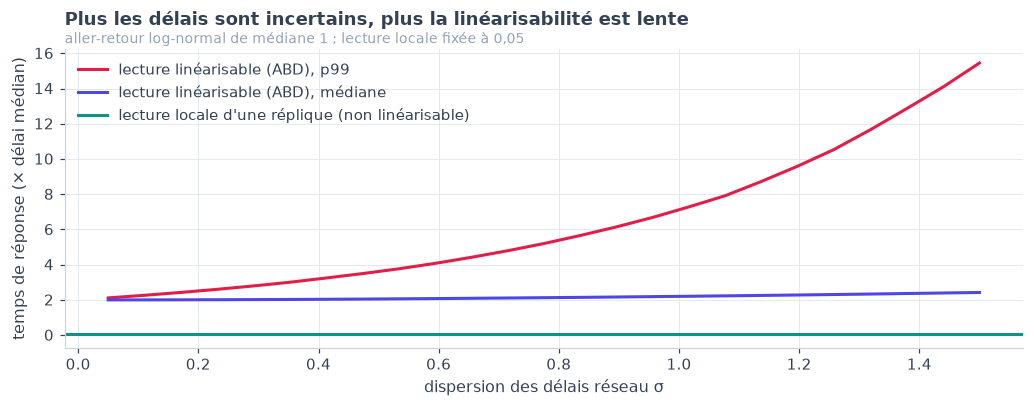

In [13]:
sig = np.linspace(0.05, 1.5, 25)
loc, abd_p50, abd_p99 = [], [], []
for s in sig:
    one = cs.quorum_latency(3, 2, sigma=s, local=False, seed=1)
    two = one + cs.quorum_latency(3, 2, sigma=s, local=False, seed=2)
    abd_p50.append(np.median(two)); abd_p99.append(np.percentile(two, 99))
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(sig, abd_p99, color=ROSE, label="lecture linéarisable (ABD), p99")
ax.plot(sig, abd_p50, color=INDIGO, label="lecture linéarisable (ABD), médiane")
ax.axhline(0.05, color=TEAL, label="lecture locale d'une réplique (non linéarisable)")
ax.set_xlabel("dispersion des délais réseau σ")
ax.set_ylabel("temps de réponse (× délai médian)")
ax.set_title("Plus les délais sont incertains, plus la linéarisabilité est lente")
subtitle(ax, "aller-retour log-normal de médiane 1 ; lecture locale fixée à 0,05")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

La médiane d'une lecture ABD reste proche de deux allers-retours, mais son p99 explose
avec la dispersion (de 2 à plus de 15 délais médians) : sur un réseau aux délais très
variables (la norme, chapitre 9), les opérations linéarisables sont
inévitablement lentes. Des modèles plus faibles peuvent être beaucoup plus rapides ; le
chapitre 13 discute de moyens d'éviter la linéarisabilité sans sacrifier la
correction.

> **À retenir.** Pendant une partition, un système linéarisable devient indisponible pour
> une partie des clients (CP) ; un système disponible ne peut pas être linéarisable (AP).
> Mais la vraie raison d'y renoncer est la **latence**, permanente et proportionnelle à
> l'incertitude des délais réseau. CAP, trop étroit, aide peu à concevoir.

## Synthèse

- La **linéarisabilité** donne l'illusion d'une copie unique modifiée atomiquement : on
  peut placer un point instantané dans chaque opération, dans l'ordre du temps réel.
  C'est une **garantie de fraîcheur**, différente de la **sérialisabilité** (isolation des
  transactions) ; les deux réunies forment la sérialisabilité stricte.
- On la **teste** en cherchant un ordre séquentiel valide de l'historique (vérificateur
  à la Knossos/Porcupine), ce qui révèle des anomalies invisibles à l'œil nu.
- Elle est nécessaire pour les **verrous, baux et élections**, les **contraintes
  d'unicité** et quand **deux canaux** de communication peuvent faire la course.
- Leader unique et consensus peuvent la fournir ; multi-leader et sans leader non, même
  avec des quorums stricts, sauf réparation synchrone (ABD), et jamais pour un CAS.
- Son coût : l'**indisponibilité** pendant une partition (CAP) et surtout une **latence**
  proportionnelle à l'incertitude des délais réseau.

Liens : la réplication et les quorums au chapitre 6, la sérialisabilité
au chapitre 8, les délais et les horloges au chapitre 9. Le
cours suivant étudie l'**ordre** des événements et les **horloges logiques** ; les cours
3 à 5 montrent comment le consensus fournit la linéarisabilité en tolérant les pannes.